# La bolsa del S&P 500

Notebook de la dinámica de la sección 4.4 de [`2_estadistica_y_datos.md`](../2_estadistica_y_datos.md). La bolsa tiene 50 papelitos que imitan los 98 rendimientos anuales del S&P 500: una población que sí se conoce, para poner a prueba la teoría.

- **Parte 1. Colección y estimación:** con lo que sacó cada mesa, estima la media y el intervalo con sus primeros 4 papelitos, con sus 20 y con los de todo el grupo juntos.
- **Parte 2. La convergencia:** simula miles de muestras de la bolsa para ilustrar las secciones 4.1 y 4.2 de la nota.

## Instrucciones

**Para los alumnos.** Por parejas, con una bolsa por mesa:

1. Impriman la [hoja de papelitos](../../../practicas/unidad3/papelitos_bolsa_sp500.pdf), recórtenla y metan los 50 papelitos en la bolsa.
2. Uno saca un papelito sin ver y el otro anota su valor con su signo; regrésenlo y agiten la bolsa. Repitan hasta tener 20 valores, en el orden en que salieron.
3. Entreguen sus 20 valores, en ese orden y con su número de mesa, para registrarlos en la celda de captura del notebook (sección 1.1).
4. Al final, cuando el notebook revele la media de la bolsa, revisen si su intervalo la atrapa.

**Para el profesor.** Hacen falta una hoja de papelitos y una bolsa opaca por mesa. Los valores se registran en el diccionario de la sección 1.1, una entrada por mesa, y quedan guardados en el notebook al guardarlo; si el diccionario está vacío, el notebook simula una clase de 15 mesas para probarlo antes de la sesión. La bolsa y las gráficas están en el módulo [`bolsa_sp500.py`](bolsa_sp500.py).

In [ ]:
import pandas as pd
import numpy as np

from bolsa_sp500 import (
    BOLSA,
    N_INICIO,
    SEMILLA,
    SIMULACIONES,
    bolsa,
    fig_distribucion,
    fig_glivenko,
    fig_intervalos_clase,
    fig_lgn,
    fig_medias,
    fig_tcl,
    simular_clase,
    validar,
    verdad
)

pd.set_option("display.max_rows", 100)
b = bolsa()    # los 50 papelitos
v = verdad(b)  # la media y la desviación estándar de la bolsa, que se revelan al final

## Parte 1. Colección y estimación con los datos de la clase

### 1.1 La captura

Cada mesa es una entrada del diccionario: `mesa_` con su número y la lista de sus 20 valores en por ciento, en el orden en que salieron, con su signo. La validación avisa de las muestras que no tienen 20 valores, que deja fuera hasta que se corrijan, y de los valores que no están en la bolsa, que suelen ser errores de captura. Un error de signo no se detecta, porque cada valor tiene su negativo en la bolsa.

In [2]:
# "mesa_número": [los 20 valores en el orden en que salieron, en por ciento]
datos = {
    # "mesa_1": [15, -5, 25, 15, 5, 35, -15, 15, 25, 5, 15, 45, -5, 15, 35, 25, 5, 15, -25, 15],
}

In [3]:
if not datos:
    print("no hay datos registrados: se usa una clase simulada")
    datos = simular_clase()
muestras = validar(datos, b)
print(f"{len(datos)} mesas registradas, {len(muestras)} muestras válidas")

no hay datos registrados: se usa una clase simulada
AVISO mesa_4: tiene 19 valores y deben ser 20; se omite hasta que lo corrija
AVISO mesa_6: +1.5% no esta en la bolsa; revisa la captura
15 mesas registradas, 14 muestras válidas


### 1.2 Cada mesa, con 4 y con 20 papelitos

Para cada muestra, la media $\bar{x}$, la desviación estándar $s$ (con divisor $n - 1$), el error estándar $s/\sqrt{n}$ y el intervalo al 95%, $\bar{x} \pm 1.96\, s/\sqrt{n}$, como en la sección 4.3 de la nota: primero con los primeros 4 papelitos de cada mesa y después con sus 20.

In [4]:
def estimar(x):
    # Media, desviación estándar, error estándar e intervalo al 95% de una muestra
    n = len(x)
    media, s = x.mean(), x.std(ddof=1)
    ee = s / np.sqrt(n)
    return {"n": n, "media": media, "s": s, "ee": ee,
            "bajo": media - 1.96 * ee, "alto": media + 1.96 * ee}


filas = []
for m in muestras:
    fila = {"mesa": m["mesa"]}
    for x in (m["valores"][:N_INICIO], m["valores"]):
        e = estimar(x)
        fila.update({f"{clave}_{e['n']}": valor for clave, valor in e.items() if clave != "n"})
    filas.append(fila)
tabla = pd.DataFrame(filas)
tabla.round(2)

,mesa,media_4,s_4,ee_4,bajo_4,alto_4,media_20,s_20,ee_20,bajo_20,alto_20
0,mesa_1,2.50,29.86,14.93,-26.76,31.76,12.00,19.76,4.42,3.34,20.66
1,mesa_2,25.00,21.60,10.80,3.83,46.17,13.50,15.99,3.57,6.49,20.51
2,mesa_3,12.50,20.62,10.31,-7.70,32.70,11.00,19.57,4.38,2.42,19.58
3,mesa_5,15.00,8.16,4.08,7.00,23.00,11.00,14.65,3.28,4.58,17.42
4,mesa_6,-3.38,21.85,10.92,-24.78,18.03,7.32,24.71,5.53,-3.51,18.16
5,mesa_7,20.00,12.91,6.45,7.35,32.65,13.00,17.65,3.95,5.26,20.74
6,mesa_8,12.50,5.00,2.50,7.60,17.40,10.50,22.12,4.95,0.81,20.19
7,mesa_9,15.00,25.82,12.91,-10.30,40.30,9.50,22.59,5.05,-0.40,19.40
8,mesa_10,7.50,18.93,9.46,-11.05,26.05,13.00,18.24,4.08,5.01,20.99
9,mesa_11,15.00,14.14,7.07,1.14,28.86,12.50,13.72,3.07,6.49,18.51


Todos sacaron de la misma bolsa: ¿por qué hay mesas que concluyen con 4 papelitos que el S&P 500 pierde y otras que gana 25% al año? Con 20, las medias se juntan, porque su dispersión baja con $\sqrt{n}$, y el intervalo de cada mesa se angosta.

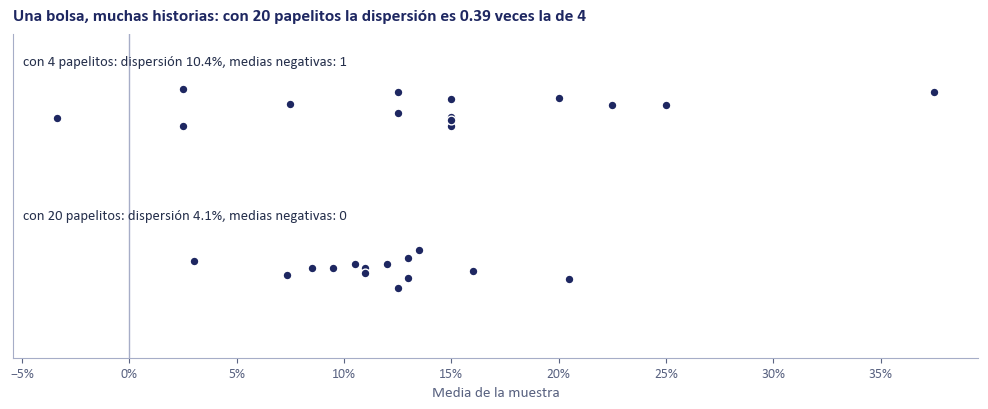

In [5]:
fig_medias(tabla)

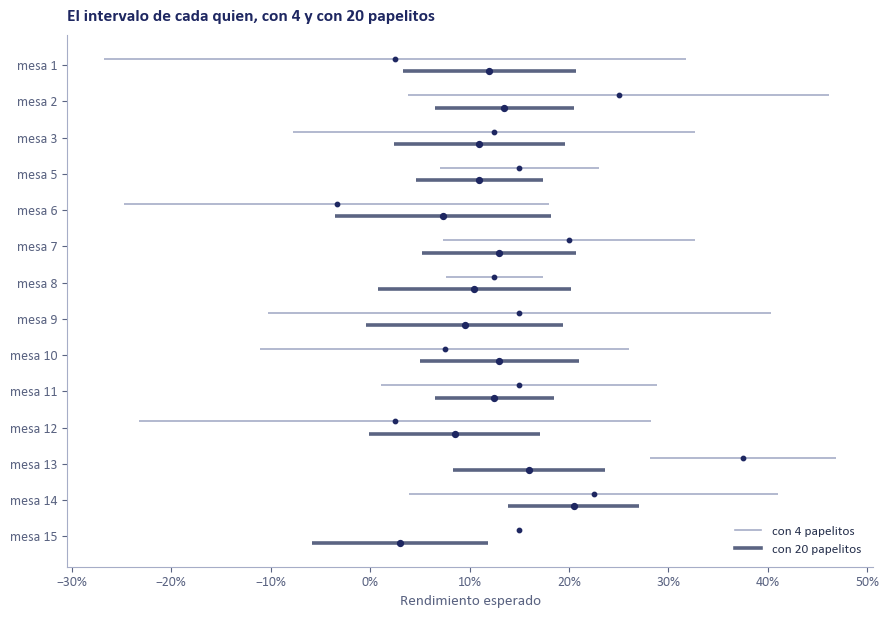

In [6]:
fig_intervalos_clase(tabla)

### 1.3 El grupo: todas las muestras juntas

Todos sacaron con reemplazo de bolsas iguales, así que juntar las muestras da una sola muestra aleatoria, de 20 papelitos por mesa, y la misma fórmula da un intervalo mucho más angosto.

el grupo junta 280 papelitos: media 11.52%, s 18.87%, error estándar 1.13%
intervalo al 95%: de 9.31% a 13.73%, 4.4 puntos de ancho, frente a 16.6 de una mesa típica con 20 papelitos y 37.1 con 4


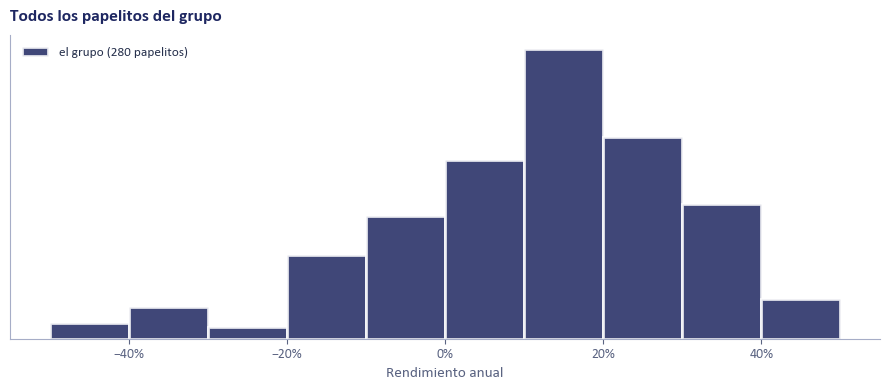

In [7]:
todas = np.concatenate([m["valores"] for m in muestras])
grupo = estimar(todas)
print(f"el grupo junta {grupo['n']} papelitos: media {grupo['media']:.2f}%, s {grupo['s']:.2f}%, "
      f"error estándar {grupo['ee']:.2f}%")
print(f"intervalo al 95%: de {grupo['bajo']:.2f}% a {grupo['alto']:.2f}%, "
      f"{grupo['alto'] - grupo['bajo']:.1f} puntos de ancho, frente a "
      f"{(tabla['alto_20'] - tabla['bajo_20']).median():.1f} de una mesa típica con 20 papelitos "
      f"y {(tabla['alto_4'] - tabla['bajo_4']).median():.1f} con 4")
fig_distribucion(todas)

### 1.4 La verdad de la bolsa

Cada papelito lleva el centro de un intervalo de 10 puntos, y hay tantos de cada valor como años cayeron en ese intervalo, a escala de 50. ¿Cuántos intervalos atrapan la media de la bolsa? Con 4 papelitos, menos de los que promete el 95%: con tan pocos datos, $s$ suele quedar corta.

In [8]:
print(f"la bolsa: media {v['media']:.2f}%, desviación estándar {v['sigma']:.2f}% (divisor n), "
      f"VaR al 95% {v['var95']:.0f}%, {100 * v['p_perder']:.0f}% de papelitos con pérdida")
pd.Series(BOLSA, name="papelitos").rename_axis("rendimiento (%)").to_frame().T

la bolsa: media 11.80%, desviación estándar 19.44% (divisor n), VaR al 95% -25%, 26% de papelitos con pérdida


rendimiento (%),-45,-35,-25,-15,-5,5,15,25,35,45
papelitos,1,1,1,3,7,7,12,9,7,2


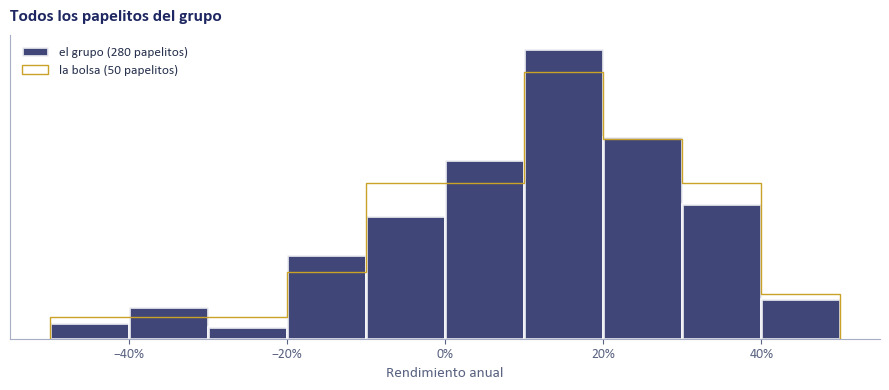

In [9]:
fig_distribucion(todas, b)

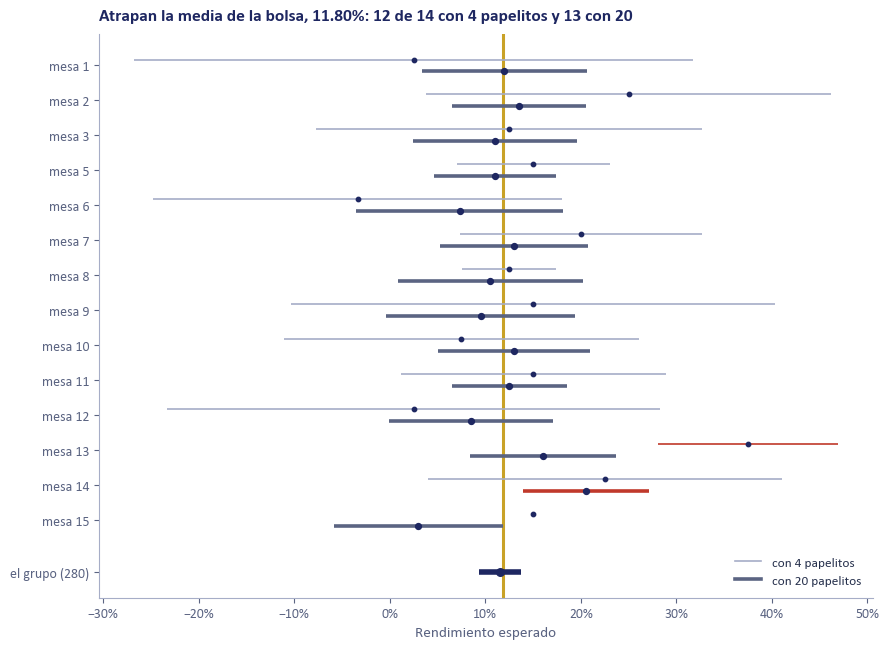

In [10]:
fig_intervalos_clase(tabla, grupo, v)

## Parte 2. La convergencia

La bolsa es una población que sí se conoce, así que se puede sacar de ella tantas veces como se quiera. Cada celda empieza su propio generador con la misma semilla, para que sus cifras no dependan del orden en que se corran.

### 2.1 Ley de los grandes números (sección 4.1)

Cinco mesas que no paran de sacar papelitos: la media de los primeros $n$ se acerca a la de la bolsa y casi siempre queda dentro de $\mu \pm 1.96\,\sigma/\sqrt{n}$, una banda que se angosta con $\sqrt{n}$.

media después de 4, 20, 100 y 1,000 papelitos:
[[ 2.5  12.   12.8  11.43]
 [20.   11.   13.6  13.25]
 [ 5.    5.5  10.5  11.48]
 [-2.5   8.5   9.5  11.18]
 [30.   20.   13.7  12.2 ]]


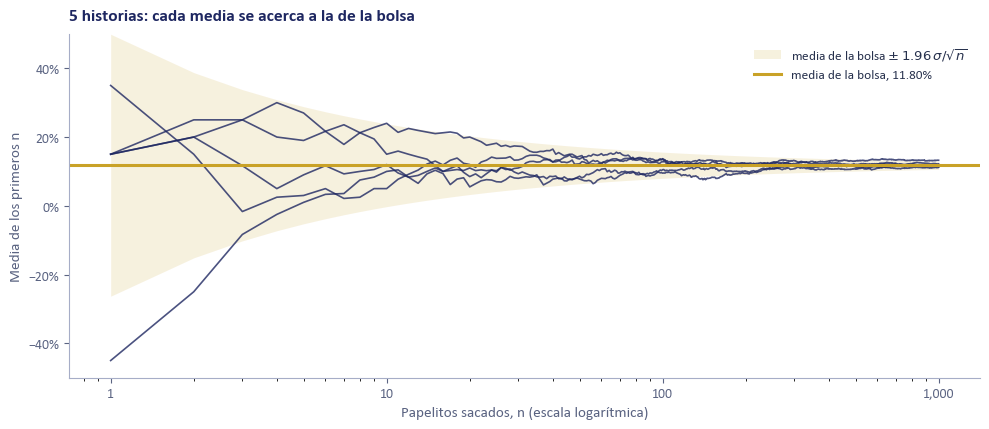

In [11]:
rng = np.random.default_rng(SEMILLA)
x = rng.choice(b, size=(5, 1000))
n = np.arange(1, 1001)
trayectorias = x.cumsum(axis=1) / n
print("media después de 4, 20, 100 y 1,000 papelitos:")
print(trayectorias[:, [3, 19, 99, 999]].round(2))
fig_lgn(trayectorias, v)

### 2.2 Glivenko-Cantelli (sección 4.1)

No solo la media: toda la distribución empírica $\hat{F}_n$, la proporción de papelitos de la muestra que no pasan de cada valor, se acerca a la de la bolsa, $F$. La distancia es la mayor diferencia vertical entre las dos escaleras.

n =     4: distancia 0.240
n =    20: distancia 0.190
n =   100: distancia 0.060
n = 1,000: distancia 0.015


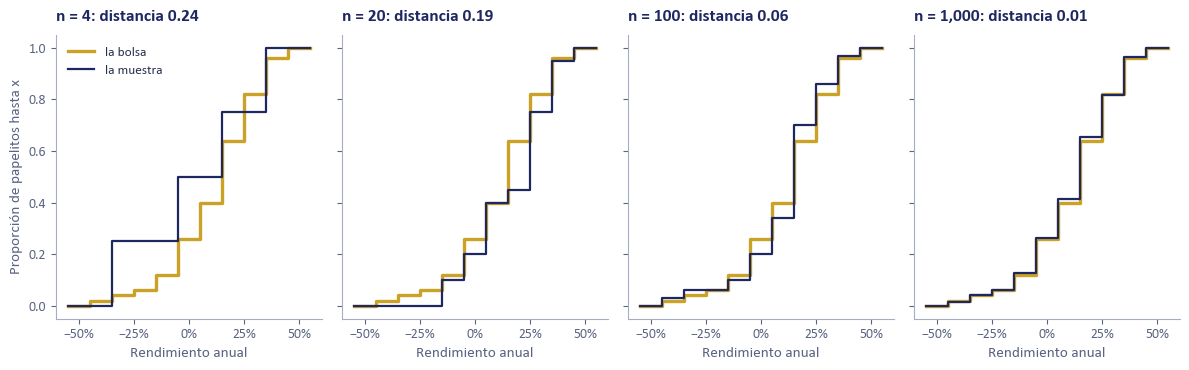

In [12]:
rng = np.random.default_rng(SEMILLA)
valores = np.array(sorted(BOLSA), dtype=float)
f_bolsa = np.array([np.mean(b <= y) for y in valores])
empiricas = {}
for n in (4, 20, 100, 1000):
    x = rng.choice(b, size=n)
    empiricas[n] = np.array([np.mean(x <= y) for y in valores])
    print(f"n = {n:5,}: distancia {np.max(np.abs(empiricas[n] - f_bolsa)):.3f}")
fig_glivenko(valores, f_bolsa, empiricas)

### 2.3 Teorema central del límite (sección 4.2)

Las medias de 10,000 muestras de 1, 4, 20 y 100 papelitos. Aunque la bolsa está cargada a la izquierda, con 4 papelitos las medias ya se parecen a la normal, y su desviación baja como $\sigma/\sqrt{n}$.

n =   1: desviación de las medias 19.36%, σ/√n 19.44%, medias negativas 25.9%
n =   4: desviación de las medias 9.85%, σ/√n 9.72%, medias negativas 10.1%
n =  20: desviación de las medias 4.34%, σ/√n 4.35%, medias negativas 0.4%
n = 100: desviación de las medias 1.96%, σ/√n 1.94%, medias negativas 0.0%


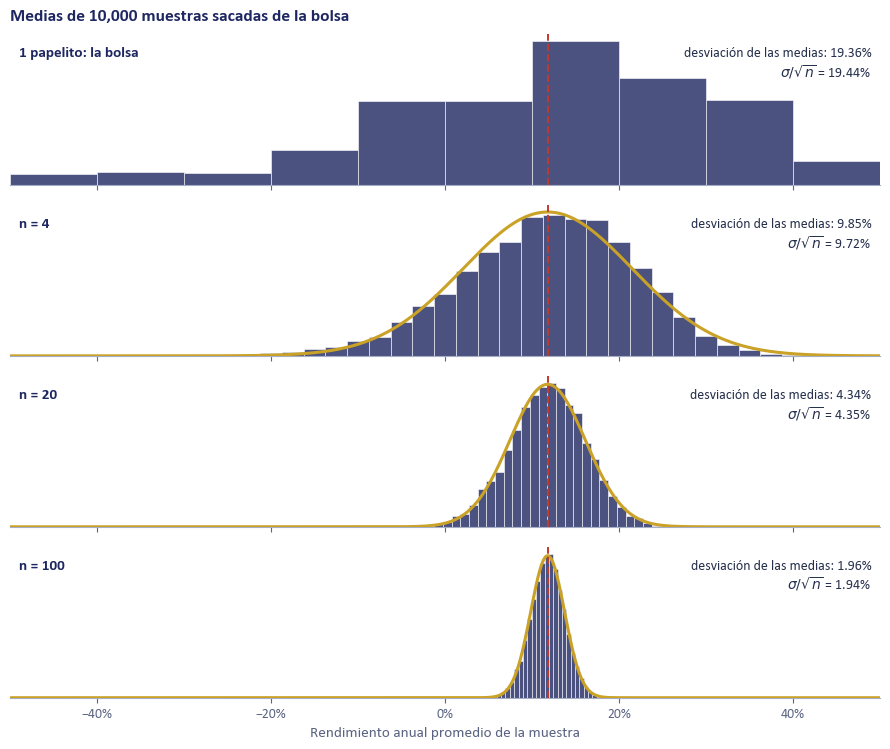

In [13]:
rng = np.random.default_rng(SEMILLA)
medias = {n: rng.choice(b, size=(SIMULACIONES, n)).mean(axis=1) for n in (1, 4, 20, 100)}
for n, m in medias.items():
    print(f"n = {n:3d}: desviación de las medias {m.std():.2f}%, "
          f"σ/√n {v['sigma'] / np.sqrt(n):.2f}%, medias negativas {100 * np.mean(m < 0):.1f}%")
fig_tcl(medias, v)